# Lab 2: Windowing - Variant 10
## Objective and assigned parameters
Study the effects of window functions on leakage, frequency separation and detection of weak tones.

f1 = 300 Hz, f2 = 300.25 Hz, f3 = 299.75 Hz; fs = 400 Hz; N = 2000.
A1 = 3, A2 = 0.3, A3 = 0.03. The table amplitude is interpreted as A1, following the Variants instructions, not as the measured peak of the summed signal.

The record duration is 5 s and the original DFT spacing is 0.2 Hz. Adjacent tones are separated by 0.25 Hz = 1.25 DFT bins.

## Aliasing
The Nyquist frequency is 200 Hz. The assigned tones alias to 100, 99.75 and 100.25 Hz respectively. Each sine has a sign inversion under this mapping. The exact assigned frequencies are used to generate the samples; plots use their observable one-sided frequencies. A spectrum near 300 Hz would be outside the unique one-sided frequency interval.


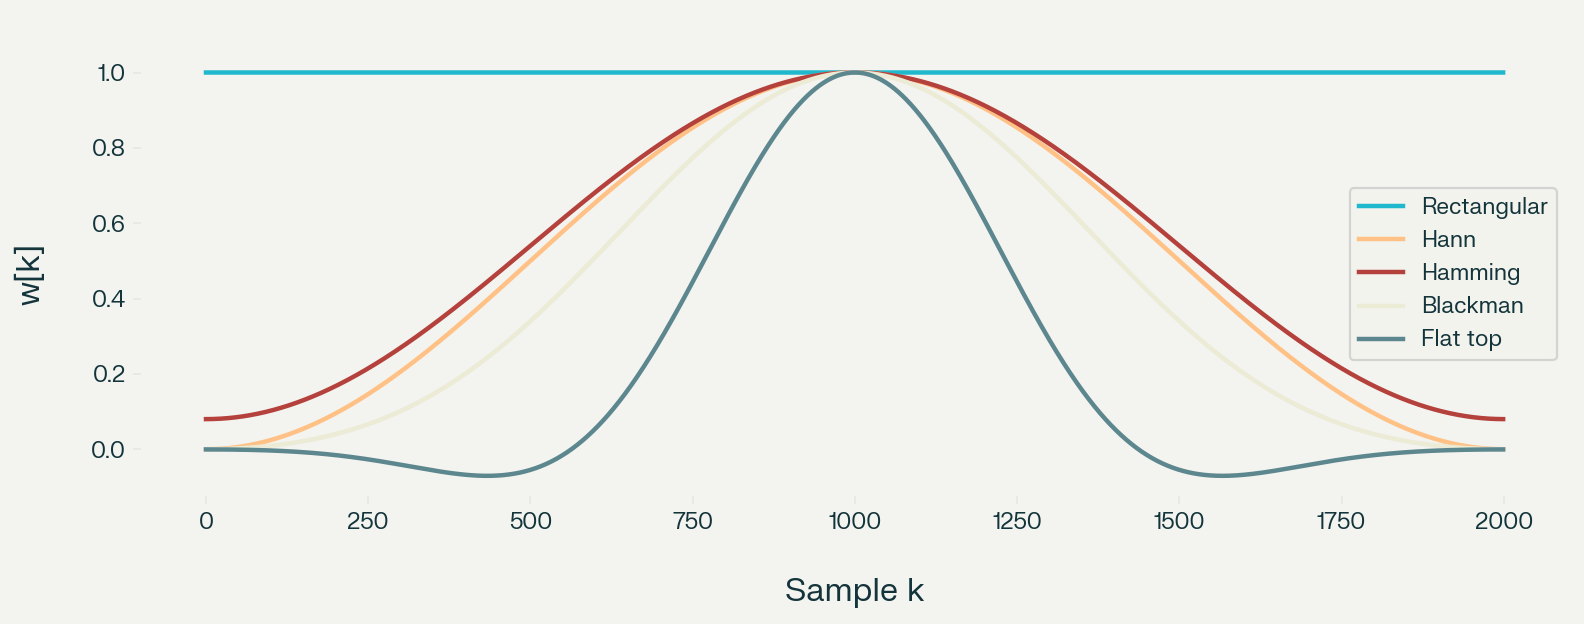

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import windows
fs, N = 400, 2000
freqs = np.array([300.0, 300.25, 299.75])
amps = np.array([3.0, 0.3, 0.03])
k = np.arange(N)
x = np.sum(amps[:, None] * np.sin(2*np.pi*freqs[:, None]*k/fs), axis=0)
ws = {"Rectangular": np.ones(N),
      "Hann": windows.hann(N, sym=False),
      "Hamming": windows.hamming(N, sym=False),
      "Blackman": windows.blackman(N, sym=False),
      "Flat top": windows.flattop(N, sym=False)}
plt.figure(figsize=(10, 4))
for name, w in ws.items():
    plt.plot(k, w, label=name)
plt.xlabel("Sample k"); plt.ylabel("w[k]")
plt.legend(); plt.grid(); plt.tight_layout(); plt.show()


## Normalization and plotting
For positive frequencies away from DC and Nyquist, the amplitude estimate is 2*abs(FFT(x*w))/sum(w). DC and Nyquist are not doubled. This corrects coherent gain and allows a fair amplitude comparison between windows. Signal levels are 20*log10(amplitude/A1), so isolated tones would have levels 0, -20 and -40 dB. These reference levels are not guaranteed peak levels in a mixture with overlapping lobes.

The handout example uses 2/N without coherent-gain correction. That convention includes window attenuation; this report explicitly corrects it. The window DTFT is separately normalized to its own maximum.

Zero-padding by a factor of 100 provides a 0.002 Hz plotting grid, not improved physical resolving power. Original DFT samples are shown as dots. Red crosses indicate expected tone locations and amplitudes, not detected peaks.


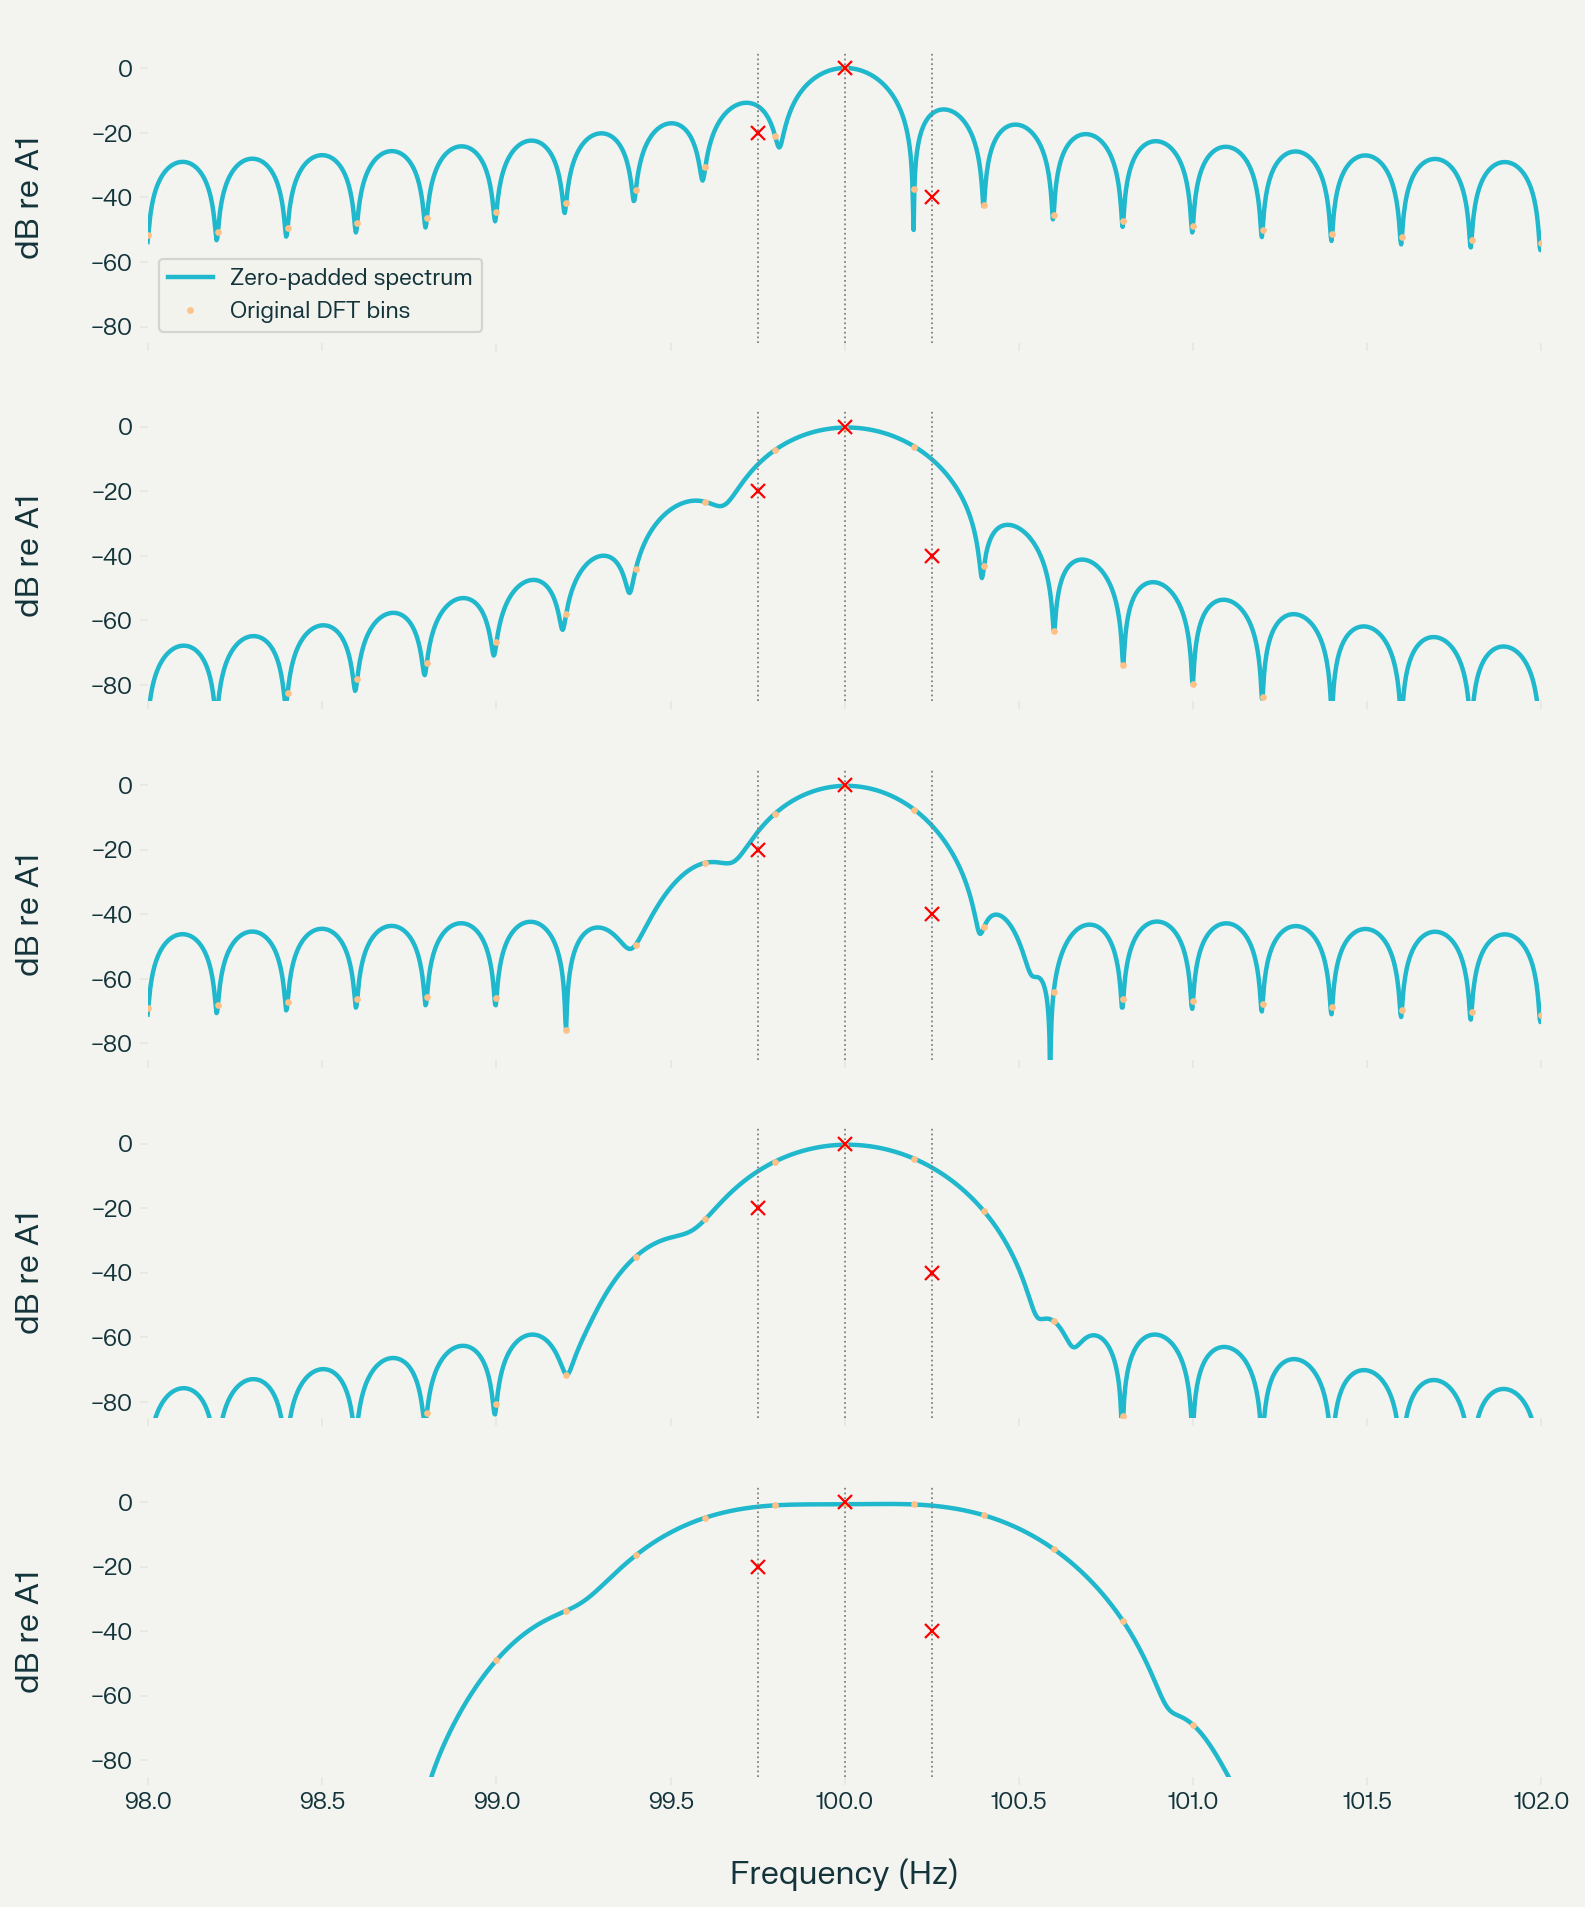

In [2]:
def amplitude_spectrum(x, w, fs, nfft):
    a = 2*np.abs(np.fft.rfft(x*w, n=nfft))/np.sum(w)
    a[0] /= 2
    if nfft % 2 == 0:
        a[-1] /= 2
    return np.fft.rfftfreq(nfft, 1/fs), a

def db(a):
    return 20*np.log10(np.maximum(a, 1e-12))

fig, axs = plt.subplots(len(ws), 1, figsize=(10, 12), sharex=True)
for ax, (name, w) in zip(axs, ws.items()):
    f, a = amplitude_spectrum(x, w, fs, 100*N)
    f0, a0 = amplitude_spectrum(x, w, fs, N)
    ax.plot(f, db(a/amps[0]), label="Zero-padded spectrum")
    ax.plot(f0, db(a0/amps[0]), '.', ms=4, label="Original DFT bins")
    for fa, level in zip([100, 99.75, 100.25], [0, -20, -40]):
        ax.axvline(fa, color="gray", ls=":", lw=0.8)
        ax.plot(fa, level, 'rx')
    ax.set(xlim=(98, 102), ylim=(-85, 5), ylabel="dB re A1", title=name)
    ax.grid()
axs[0].legend(loc="lower left")
axs[-1].set_xlabel("Frequency (Hz)")
plt.tight_layout(); plt.show()


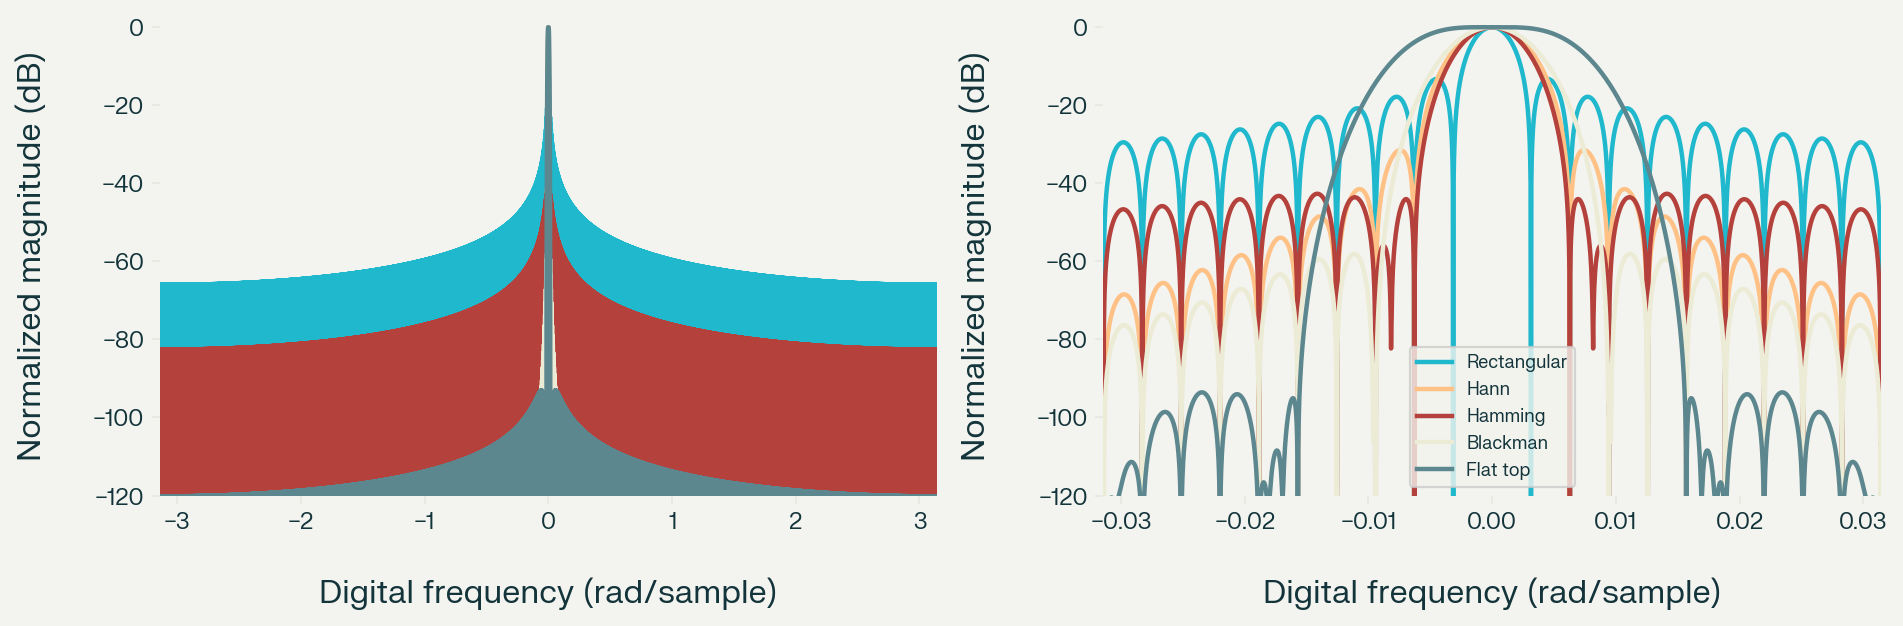

In [3]:
def window_dtft(w, factor=100):
    nfft = factor*len(w)
    omega = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(nfft))
    W = np.abs(np.fft.fftshift(np.fft.fft(w, nfft)))
    return omega, db(W/W.max())

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for name, w in ws.items():
    omega, level = window_dtft(w)
    for ax in axs:
        ax.plot(omega, level, label=name)
for ax in axs:
    ax.set(ylim=(-120, 3), xlabel="Digital frequency (rad/sample)",
           ylabel="Normalized magnitude (dB)")
    ax.grid()
axs[0].set_xlim(-np.pi, np.pi)
axs[1].set_xlim(-np.pi/100, np.pi/100)
axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


## Interpretation and conclusions
1. Rectangular has the narrowest main lobe, but large sidelobes. Its apparent nearby maxima cannot automatically be identified as weak tones. The computed maximum near 99.718 Hz is about -10.66 dB, not the expected -20 dB tone at 99.75 Hz. A maximum near 100.284 Hz is about -12.72 dB, far above the -40 dB tone at 100.25 Hz: leakage dominates.
2. Hann and Hamming reduce sidelobes but broaden the main lobe. Neither produces three separate, trustworthy tone peaks in this record. The near-100 Hz lobes overlap strongly; low sidelobes alone cannot remove overlap inside a strong tone's main lobe.
3. Blackman suppresses distant sidelobes more strongly, but its broader main lobe merges the close tones. It gives only one local maximum between 99.5 and 100.5 Hz in this simulation.
4. Flat top is included to match the introductory example. Its broad main lobe favors amplitude estimation of isolated tones, not separation of this mixture. It also gives only one local maximum in that interval.
5. No tested window reliably reveals all three components with the assigned 5 s record and 40 dB amplitude range. Rectangular offers the narrowest lobe, whereas tapered windows improve rejection of sufficiently distant strong-tone leakage. There is no universally best window for close, unequal tones.
6. Small frequency differences matter because of amplitude differences, main-lobe overlap and alignment with DFT bins. The main tone is at bin 500; the other two aliases are at bin coordinates 498.75 and 501.25. The main tone alone is bin-centered and has no rectangular-window leakage at other original DFT bins, yet its continuous finite-record spectrum still has sidelobes between those bins. The weak tones are off-bin.
7. A longer observation would narrow the lobes and improve separation. Increasing only the zero-padding does not add information or separate unresolved tones. The assigned sample rate also prevents recovering the original analog frequencies uniquely without prior information.


## Sources and submission
- Laboratory handout: DigitalSignalProcessing.pdf, pages 4 and 6-13, especially Table 1, variant 10.
- SciPy Signal Processing tutorial: https://docs.scipy.org/doc/scipy-1.18.0/tutorial/signal.html (windowing, spectral normalization and aliasing).

Repository URL: [add your repository URL after uploading]. No repository has been created or uploaded automatically. Submit the report PDF, executed notebook and notebook PDF export as requested by the handout.
